# **Pipeline de modelos con los datos imputados**

Este notebook repite el pipeline de `fit_models.ipynb` y `model_comparison.ipynb`
(los 10 modelos jerárquicos, elastic net, la validación cruzada, la comparación
de modelos, los supuestos y el diagnóstico de residuos) sobre las 20 bases de
la imputación múltiple de `imputacion.ipynb` (N = 669 por base), en lugar de los
530 casos completos.

Cada paso se corre por separado en cada base y los resultados se combinan así:

| Resultado | Cómo se combina |
|---|---|
| Coeficientes y EE de los `lm()` | Reglas de Rubin: el coeficiente es el promedio; la varianza suma la de dentro de las bases y la de entre bases |
| R², log L, AIC, BIC, ΔR², f², ΔAIC, ΔBIC | Promedio entre bases |
| RMSE y R² de la validación cruzada | Promedio entre bases; el EE se combina con las reglas de Rubin |
| Elastic net | En cuántas bases queda cada columna y su coeficiente medio |
| Supuestos | En cuántas de las 20 bases se cumple cada uno |
| Diagnóstico de residuos | Promedio entre bases; los gráficos superponen las 20 bases |


## *Carga de paquetes y configuración*

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(gt)
})

# Parche para que las tablas gt se vean en Jupyter (mismo del EDA)
repr_html.gt_tbl <- function(obj, ...) gt::as_raw_html(obj)
repr_markdown.gt_tbl <- function(obj, ...) NULL
repr_latex.gt_tbl <- function(obj, ...) NULL
for (g in c("repr_html", "repr_markdown", "repr_latex")) {
  registerS3method(g, "gt_tbl", get(paste0(g, ".gt_tbl")), envir = asNamespace("repr"))
}

# Las rutas de config.R son relativas a la raíz del proyecto.
if (!file.exists("myst.yml") && file.exists("../myst.yml")) setwd("..")

if (file.exists(".Renviron")) readRenviron(".Renviron")

source("R/config.R")
source("R/data_prep.R")
source("R/moderation_pipeline.R")
source("R/model_comparison.R")
source("R/cross_validation.R")
source("R/elastic_net.R")
source("R/imputed_pipeline.R")

col_morado <- viridisLite::viridis(10, end = 0.8)[1]
col_verde  <- viridisLite::viridis(10, end = 0.8)[10]

## *Bases imputadas*

`load_imputed_datasets()` lee las 20 bases que guarda `imputacion.ipynb`.
Todas tienen los mismos estudiantes en el mismo orden; solo cambian los valores
imputados.

In [2]:
bases <- load_imputed_datasets()
imputed <- imputed_rows(bases)

cat(sprintf("Bases imputadas:            %d\n", length(bases)))
cat(sprintf("Estudiantes por base:       %d\n", nrow(bases[[1]])))
cat(sprintf("Con algún valor imputado:   %d (%.1f %%)\n", sum(imputed), 100 * mean(imputed)))

Bases imputadas:            20


Estudiantes por base:       669


Con algún valor imputado:   136 (20.3 %)


### *Preprocesamiento*

Se aplica el preprocesamiento del pipeline (niveles de referencia, centrado del
apoyo y codificación del género) con **los mismos parámetros en todas las
bases**: las grandes medias son el promedio de las medias de las 20 bases. Así
cada coeficiente significa lo mismo en todas y se pueden combinar.

In [3]:
mi_params <- learn_mi_preprocessing(bases)
analytic  <- prepare_mi(bases, mi_params)

tibble(Variable = names(mi_params$grand_means), `Gran media` = mi_params$grand_means) %>%
  bind_rows(tibble(Variable = paste("Referencia:", names(mi_params$reference_levels)),
                   `Gran media` = NA_real_)) %>%
  mutate(Valor = ifelse(is.na(`Gran media`),
                        unlist(mi_params$reference_levels)[str_remove(Variable, "Referencia: ")],
                        sprintf("%.4f", `Gran media`))) %>%
  select(Variable, Valor) %>%
  gt() %>%
  tab_header(title = "Parámetros de preprocesamiento comunes a las 20 bases")

<div id="fajjwbmmyc" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#fajjwbmmyc table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#fajjwbmmyc thead, #fajjwbmmyc tbody, #fajjwbmmyc tfoot, #fajjwbmmyc tr, #fajjwbmmyc td, #fajjwbmmyc th {
  border-style: none;
}

#fajjwbmmyc p {
  margin: 0;
  padding: 0;
}

#fajjwbmmyc .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#fajjwbmmyc .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#fajjwbmmyc .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#fajjwbmmyc .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#fajjwbmmyc .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#fajjwbmmyc .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#fajjwbmmyc .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#fajjwbmmyc .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#fajjwbmmyc .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#fajjwbmmyc .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#fajjwbmmyc .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#fajjwbmmyc .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#fajjwbmmyc .gt_spanner_row {
  border-bottom-style: hidden;
}

#fajjwbmmyc .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Composición de la muestra*

Frecuencia media de cada nivel entre las 20 bases. El nivel de referencia de
cada factor va marcado con `(ref)`.

In [4]:
map_dfr(seq_along(analytic), function(i) {
  map_dfr(CATEGORICAL_VARS, function(v) {
    analytic[[i]] %>% count(Nivel = .data[[v]], name = "n") %>%
      mutate(Variable = v, ref = Nivel == levels(analytic[[i]][[v]])[1], Nivel = as.character(Nivel))
  })
}) %>%
  group_by(Variable, Nivel) %>%
  summarise(ref = first(ref), n = mean(n), .groups = "drop") %>%
  mutate(Variable = factor(Variable, levels = CATEGORICAL_VARS),
         Nivel = ifelse(ref, paste(Nivel, "(ref)"), Nivel),
         pct = 100 * n / nrow(bases[[1]])) %>%
  arrange(Variable, desc(ref), desc(n)) %>%
  select(-ref) %>%
  gt(groupname_col = "Variable") %>%
  fmt_number(c(n, pct), decimals = 1) %>%
  cols_label(n = "n medio", pct = "%") %>%
  tab_header(title = "Composición de las bases imputadas")

<div id="sbmdhkbwms" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#sbmdhkbwms table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#sbmdhkbwms thead, #sbmdhkbwms tbody, #sbmdhkbwms tfoot, #sbmdhkbwms tr, #sbmdhkbwms td, #sbmdhkbwms th {
  border-style: none;
}

#sbmdhkbwms p {
  margin: 0;
  padding: 0;
}

#sbmdhkbwms .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#sbmdhkbwms .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#sbmdhkbwms .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#sbmdhkbwms .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#sbmdhkbwms .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#sbmdhkbwms .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#sbmdhkbwms .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#sbmdhkbwms .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#sbmdhkbwms .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#sbmdhkbwms .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#sbmdhkbwms .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#sbmdhkbwms .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#sbmdhkbwms .gt_spanner_row {
  border-bottom-style: hidden;
}

#sbmdhkbwms .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Modelos lineales jerárquicos*

Las mismas 10 fórmulas de `build_formulas()`, ajustadas con `lm()` en cada una
de las 20 bases.

In [5]:
formulas  <- build_formulas()
mi_models <- fit_mi_models(analytic, formulas)

cat(sprintf("Bases:             %d\n", length(mi_models)))
cat(sprintf("Modelos por base:  %d\n", length(mi_models[[1]])))
cat(sprintf("N por modelo:      %d\n", nobs(mi_models[[1]][[1]])))

Bases:             20


Modelos por base:  10


N por modelo:      669


### *Coeficientes combinados (reglas de Rubin)*

Para cada coeficiente, *b* es el promedio entre bases y el EE combina la
varianza dentro de las bases y entre bases. λ es la proporción de la varianza
total que se debe a los datos faltantes: cuanto mayor, más depende la
estimación de los valores imputados. No se reporta estadístico t ni p-valor.

In [6]:
coef_mi <- pool_mi_coefficients(mi_models)

coef_mi %>%
  gt(groupname_col = "model") %>%
  fmt_number(c(estimate, std_error, se_within), decimals = 4) %>%
  fmt_number(lambda, decimals = 3) %>%
  cols_label(term = "Término", estimate = "b", std_error = "EE (Rubin)",
             se_within = "EE dentro de las bases", lambda = "λ") %>%
  tab_header(title = "Coeficientes de los 10 modelos con imputación múltiple",
             subtitle = "Errores estándar OLS combinados con las reglas de Rubin")

<div id="yafmoldpel" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#yafmoldpel table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#yafmoldpel thead, #yafmoldpel tbody, #yafmoldpel tfoot, #yafmoldpel tr, #yafmoldpel td, #yafmoldpel th {
  border-style: none;
}

#yafmoldpel p {
  margin: 0;
  padding: 0;
}

#yafmoldpel .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#yafmoldpel .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#yafmoldpel .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#yafmoldpel .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#yafmoldpel .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#yafmoldpel .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#yafmoldpel .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#yafmoldpel .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#yafmoldpel .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#yafmoldpel .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#yafmoldpel .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#yafmoldpel .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#yafmoldpel .gt_spanner_row {
  border-bottom-style: hidden;
}

#yafmoldpel .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Elastic net*

El mismo procedimiento de `fit_models.ipynb` (`tune_en()`): parte de todas las
columnas de M3_joint, elige α y λ con una validación cruzada interna y la regla
de 1 EE. Se ajusta en cada base por separado.

In [8]:
en_models <- fit_mi_en(bases)

tibble(imp = seq_along(en_models),
       alpha = map_dbl(en_models, "alpha"),
       lambda = map_dbl(en_models, "lambda"),
       n_sel = map_int(en_models, ~ length(.x$selected))) %>%
  summarise(`α más elegido` = as.numeric(names(which.max(table(alpha)))),
            `Bases con ese α` = max(table(alpha)),
            `λ mediano` = median(lambda),
            `λ mínimo` = min(lambda), `λ máximo` = max(lambda),
            `Columnas distintas de cero (mediana)` = median(n_sel)) %>%
  gt() %>%
  fmt_number(starts_with("λ"), decimals = 4) %>%
  tab_header(title = "α y λ elegidos en las 20 bases")

<div id="ytjkzawvrv" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#ytjkzawvrv table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#ytjkzawvrv thead, #ytjkzawvrv tbody, #ytjkzawvrv tfoot, #ytjkzawvrv tr, #ytjkzawvrv td, #ytjkzawvrv th {
  border-style: none;
}

#ytjkzawvrv p {
  margin: 0;
  padding: 0;
}

#ytjkzawvrv .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#ytjkzawvrv .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#ytjkzawvrv .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#ytjkzawvrv .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#ytjkzawvrv .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#ytjkzawvrv .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#ytjkzawvrv .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#ytjkzawvrv .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#ytjkzawvrv .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#ytjkzawvrv .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#ytjkzawvrv .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#ytjkzawvrv .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#ytjkzawvrv .gt_spanner_row {
  border-bottom-style: hidden;
}

#ytjkzawvrv .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

In [9]:
mi_en_summary(en_models) %>%
  gt() %>%
  fmt_number(mean_estimate, decimals = 4) %>%
  cols_label(term = "Columna", n_selected = "Bases en que queda (de 20)",
             mean_estimate = "Coeficiente medio") %>%
  tab_header(title = "Columnas que selecciona elastic net")

<div id="itifbundlz" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#itifbundlz table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#itifbundlz thead, #itifbundlz tbody, #itifbundlz tfoot, #itifbundlz tr, #itifbundlz td, #itifbundlz th {
  border-style: none;
}

#itifbundlz p {
  margin: 0;
  padding: 0;
}

#itifbundlz .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#itifbundlz .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#itifbundlz .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#itifbundlz .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#itifbundlz .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#itifbundlz .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#itifbundlz .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#itifbundlz .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#itifbundlz .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#itifbundlz .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#itifbundlz .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#itifbundlz .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#itifbundlz .gt_spanner_row {
  border-bottom-style: hidden;
}

#itifbundlz .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Validación cruzada*

La misma validación cruzada repetida de `fit_models.ipynb` (10 folds × 20
repeticiones, estratificada por género y con el preprocesamiento aprendido en
cada fold) en cada una de las 20 bases, en paralelo. Las bases tienen los mismos
estudiantes en el mismo orden, así que las particiones son las mismas en todas.
El RMSE y el R² de cada modelo son el promedio entre bases, y su EE combina el
EE de la validación cruzada de cada base con la variación entre bases.

In [10]:
t0 <- Sys.time()
mi_cv <- run_mi_cv(bases, formulas = formulas)
cat(sprintf("Filas (base × partición × modelo): %d\n", nrow(mi_cv)))
cat(sprintf("Tiempo: %.1f min\n", as.numeric(difftime(Sys.time(), t0, units = "mins"))))

mi_cv_summary <- mi_summarise_cv(mi_cv)

Filas (base × partición × modelo): 44000


Tiempo: 3.7 min


In [11]:
mi_cv_summary %>%
  mutate(Estado = case_when(is_best ~ "Mejor RMSE",
                            within_se_rule ~ "Dentro de 1 EE",
                            TRUE ~ "")) %>%
  select(model, n_coef, rmse_mean, rmse_se, delta_rmse, delta_rmse_se, r2_mean, r2_se, Estado) %>%
  gt() %>%
  fmt_number(n_coef, decimals = 1) %>%
  fmt_number(c(rmse_mean, rmse_se, delta_rmse, delta_rmse_se, r2_mean, r2_se), decimals = 4) %>%
  cols_label(model = "Modelo", n_coef = "Coeficientes", rmse_mean = "RMSE", rmse_se = "EE",
             delta_rmse = "Δ RMSE vs. mejor", delta_rmse_se = "EE Δ",
             r2_mean = "R² fuera de muestra", r2_se = "EE R²") %>%
  tab_header(title = "Validación cruzada combinada entre las 20 bases",
             subtitle = sprintf("Umbral de la regla de 1 EE: RMSE ≤ %.4f",
                                attr(mi_cv_summary, "threshold")))

<div id="zqmktzinqq" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#zqmktzinqq table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#zqmktzinqq thead, #zqmktzinqq tbody, #zqmktzinqq tfoot, #zqmktzinqq tr, #zqmktzinqq td, #zqmktzinqq th {
  border-style: none;
}

#zqmktzinqq p {
  margin: 0;
  padding: 0;
}

#zqmktzinqq .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#zqmktzinqq .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#zqmktzinqq .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#zqmktzinqq .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#zqmktzinqq .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#zqmktzinqq .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#zqmktzinqq .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#zqmktzinqq .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#zqmktzinqq .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#zqmktzinqq .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#zqmktzinqq .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#zqmktzinqq .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#zqmktzinqq .gt_spanner_row {
  border-bottom-style: hidden;
}

#zqmktzinqq .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

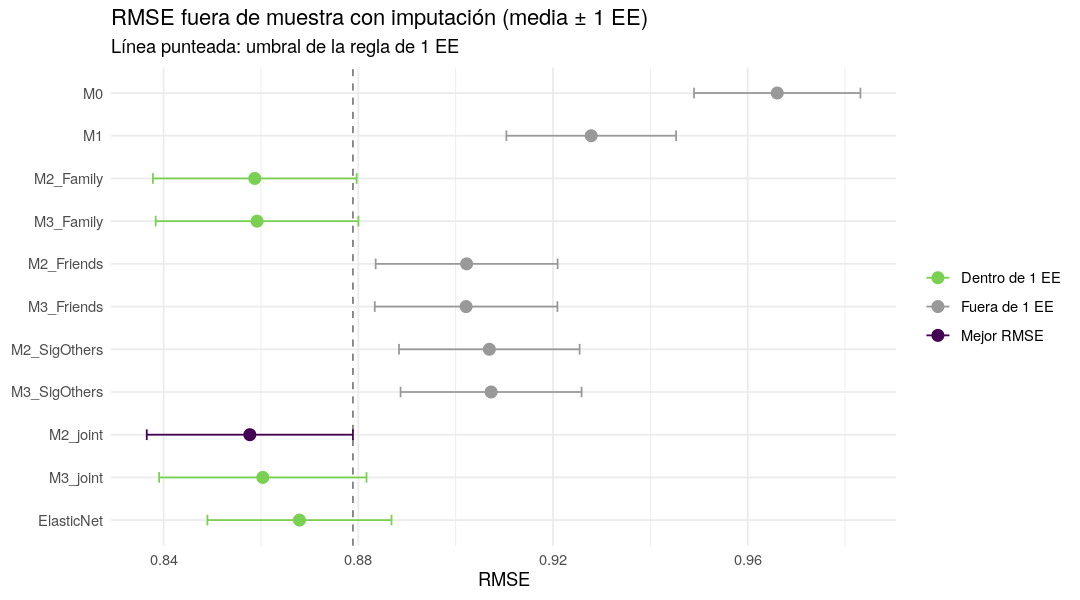

In [12]:
options(repr.plot.width = 9, repr.plot.height = 5)

mi_cv_summary %>%
  mutate(model = fct_rev(model),
         Estado = case_when(is_best ~ "Mejor RMSE",
                            within_se_rule ~ "Dentro de 1 EE",
                            TRUE ~ "Fuera de 1 EE")) %>%
  ggplot(aes(x = rmse_mean, y = model, color = Estado)) +
  geom_vline(xintercept = attr(mi_cv_summary, "threshold"),
             linetype = "dashed", color = "grey50") +
  geom_errorbar(aes(xmin = rmse_mean - rmse_se, xmax = rmse_mean + rmse_se),
                width = 0.25, orientation = "y") +
  geom_point(size = 3) +
  scale_color_manual(values = c("Mejor RMSE"     = col_morado,
                                "Dentro de 1 EE" = col_verde,
                                "Fuera de 1 EE"  = "grey60")) +
  labs(title = "RMSE fuera de muestra con imputación (media ± 1 EE)",
       subtitle = "Línea punteada: umbral de la regla de 1 EE",
       x = "RMSE", y = NULL, color = NULL) +
  theme_minimal()

## *Índices de ajuste por modelo*

R², log L, AIC y BIC promediados entre las 20 bases. ΔAIC, ΔBIC y los pesos de
Akaike se calculan sobre los promedios. *DE AIC* es la desviación estándar del
AIC entre bases: cuánto cambia por los valores imputados.

In [13]:
mi_indices <- mi_fit_indices(mi_models)

mi_indices %>%
  gt() %>%
  fmt_number(c(r_squared, adj_r_squared), decimals = 4) %>%
  fmt_number(c(log_lik, aic, aic_sd, bic, delta_aic, delta_bic), decimals = 2) %>%
  fmt_number(akaike_weight, decimals = 3) %>%
  cols_label(model = "Modelo", r_squared = "R²", adj_r_squared = "R² ajustado",
             log_lik = "log L", aic = "AIC", aic_sd = "DE AIC", bic = "BIC",
             delta_aic = "ΔAIC", delta_bic = "ΔBIC", akaike_weight = "Peso de Akaike") %>%
  tab_header(title = "Índices de ajuste promediados entre las 20 bases")

<div id="akkjbywrts" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#akkjbywrts table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#akkjbywrts thead, #akkjbywrts tbody, #akkjbywrts tfoot, #akkjbywrts tr, #akkjbywrts td, #akkjbywrts th {
  border-style: none;
}

#akkjbywrts p {
  margin: 0;
  padding: 0;
}

#akkjbywrts .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#akkjbywrts .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#akkjbywrts .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#akkjbywrts .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#akkjbywrts .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#akkjbywrts .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#akkjbywrts .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#akkjbywrts .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#akkjbywrts .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#akkjbywrts .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#akkjbywrts .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#akkjbywrts .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#akkjbywrts .gt_spanner_row {
  border-bottom-style: hidden;
}

#akkjbywrts .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

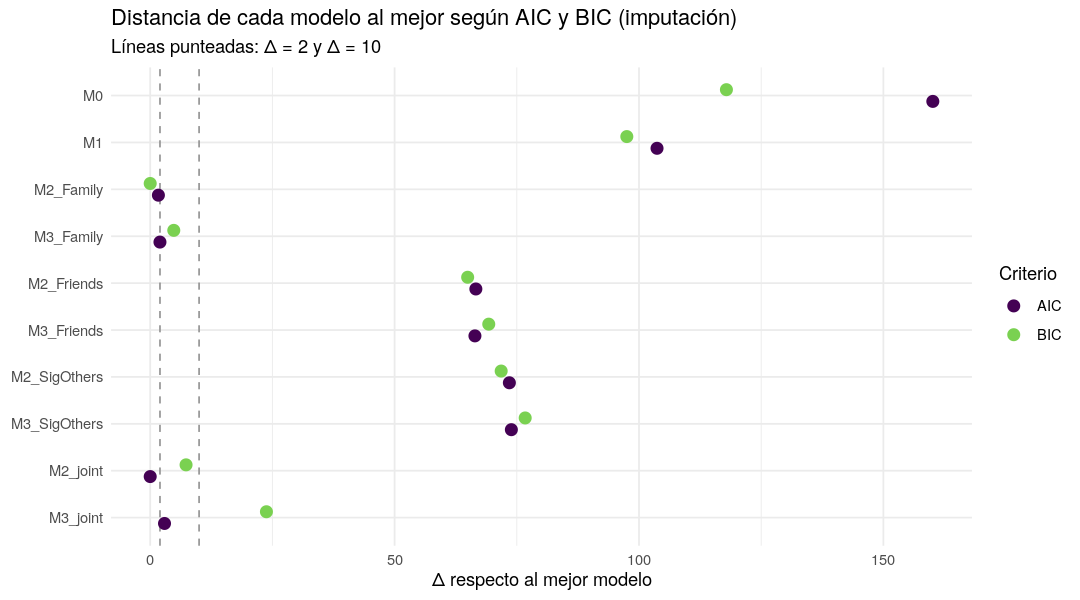

In [14]:
options(repr.plot.width = 9, repr.plot.height = 5)

mi_indices %>%
  select(model, AIC = delta_aic, BIC = delta_bic) %>%
  pivot_longer(-model, names_to = "Criterio", values_to = "delta") %>%
  mutate(model = factor(model, levels = rev(mi_indices$model))) %>%
  ggplot(aes(x = delta, y = model, color = Criterio)) +
  geom_vline(xintercept = c(2, 10), linetype = "dashed", color = "grey60") +
  geom_point(size = 3, position = position_dodge(width = 0.5)) +
  scale_color_viridis_d(end = 0.8) +
  labs(title = "Distancia de cada modelo al mejor según AIC y BIC (imputación)",
       subtitle = "Líneas punteadas: Δ = 2 y Δ = 10",
       x = "Δ respecto al mejor modelo", y = NULL) +
  theme_minimal()

## *Comparaciones entre modelos anidados*

La misma secuencia de `model_comparison.ipynb`, con ΔR², f² de Cohen, ΔAIC y
ΔBIC promediados entre bases. *Bases AIC < 0* cuenta en cuántas de las 20 bases
el AIC favorece al modelo completo.

In [15]:
mi_nested <- mi_compare_nested(mi_models)

mi_nested %>%
  mutate(paso = sprintf("%s → %s", reduced, full)) %>%
  select(paso, block, df_added, delta_r2, cohen_f2, delta_aic, delta_aic_sd, delta_bic, n_aic_favors) %>%
  gt() %>%
  fmt_number(c(delta_r2, cohen_f2), decimals = 4) %>%
  fmt_number(c(delta_aic, delta_aic_sd, delta_bic), decimals = 2) %>%
  cols_label(paso = "Paso", block = "Bloque agregado", df_added = "Coef. agregados",
             delta_r2 = "ΔR²", cohen_f2 = "f²", delta_aic = "ΔAIC", delta_aic_sd = "DE ΔAIC",
             delta_bic = "ΔBIC", n_aic_favors = "Bases AIC < 0") %>%
  tab_spanner("Varianza explicada", c(delta_r2, cohen_f2)) %>%
  tab_spanner("Criterios de información", c(delta_aic, delta_aic_sd, delta_bic, n_aic_favors)) %>%
  tab_header(title = "Comparaciones entre modelos anidados (imputación)",
             subtitle = "ΔAIC y ΔBIC: completo − reducido (negativo favorece al completo)")

<div id="xjzgdqyduw" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#xjzgdqyduw table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#xjzgdqyduw thead, #xjzgdqyduw tbody, #xjzgdqyduw tfoot, #xjzgdqyduw tr, #xjzgdqyduw td, #xjzgdqyduw th {
  border-style: none;
}

#xjzgdqyduw p {
  margin: 0;
  padding: 0;
}

#xjzgdqyduw .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#xjzgdqyduw .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#xjzgdqyduw .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#xjzgdqyduw .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#xjzgdqyduw .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#xjzgdqyduw .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#xjzgdqyduw .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#xjzgdqyduw .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#xjzgdqyduw .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#xjzgdqyduw .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#xjzgdqyduw .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#xjzgdqyduw .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#xjzgdqyduw .gt_spanner_row {
  border-bottom-style: hidden;
}

#xjzgdqyduw .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Criterios de información frente a validación cruzada*

In [16]:
mi_cv_summary %>%
  transmute(model = as.character(model), rmse_mean, delta_rmse, within_se_rule) %>%
  left_join(mi_indices %>% select(model, delta_aic, delta_bic), by = "model") %>%
  select(model, delta_aic, delta_bic, rmse_mean, delta_rmse, within_se_rule) %>%
  gt() %>%
  fmt_number(c(delta_aic, delta_bic), decimals = 2) %>%
  fmt_number(c(rmse_mean, delta_rmse), decimals = 4) %>%
  sub_missing(missing_text = "—") %>%
  text_transform(locations = cells_body(columns = within_se_rule),
                 fn = function(x) ifelse(x == "TRUE", "sí", "no")) %>%
  cols_label(model = "Modelo", delta_aic = "ΔAIC", delta_bic = "ΔBIC",
             rmse_mean = "RMSE (CV)", delta_rmse = "Δ RMSE vs. mejor",
             within_se_rule = "Dentro de 1 EE") %>%
  tab_header(title = "AIC, BIC y validación cruzada (imputación)")

<div id="znituwjaex" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#znituwjaex table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#znituwjaex thead, #znituwjaex tbody, #znituwjaex tfoot, #znituwjaex tr, #znituwjaex td, #znituwjaex th {
  border-style: none;
}

#znituwjaex p {
  margin: 0;
  padding: 0;
}

#znituwjaex .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#znituwjaex .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#znituwjaex .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#znituwjaex .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#znituwjaex .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#znituwjaex .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#znituwjaex .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#znituwjaex .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#znituwjaex .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#znituwjaex .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#znituwjaex .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#znituwjaex .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#znituwjaex .gt_spanner_row {
  border-bottom-style: hidden;
}

#znituwjaex .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Elastic net frente a los modelos jerárquicos: ΔR²*

ΔR² = R² de elastic net − R² del modelo jerárquico, dentro de muestra (promedio
entre bases) y fuera de muestra (validación cruzada combinada).

In [17]:
r2_en_in  <- mean(map2_dbl(en_models, bases, en_r_squared))
r2_en_oos <- mi_cv_summary$r2_mean[mi_cv_summary$model == EN_MODEL_NAME]

mi_indices %>%
  select(model, r2_in = r_squared) %>%
  left_join(mi_cv_summary %>% transmute(model = as.character(model), r2_oos = r2_mean),
            by = "model") %>%
  mutate(delta_in = r2_en_in - r2_in, delta_oos = r2_en_oos - r2_oos) %>%
  gt() %>%
  fmt_number(-model, decimals = 4) %>%
  cols_label(model = "Modelo", r2_in = "R² dentro", r2_oos = "R² fuera",
             delta_in = "ΔR² dentro", delta_oos = "ΔR² fuera") %>%
  tab_header(title = "Elastic net frente a cada modelo jerárquico (imputación)",
             subtitle = sprintf("R² de elastic net: %.4f dentro de muestra, %.4f fuera de muestra",
                                r2_en_in, r2_en_oos))

<div id="mgdxupcrzr" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#mgdxupcrzr table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#mgdxupcrzr thead, #mgdxupcrzr tbody, #mgdxupcrzr tfoot, #mgdxupcrzr tr, #mgdxupcrzr td, #mgdxupcrzr th {
  border-style: none;
}

#mgdxupcrzr p {
  margin: 0;
  padding: 0;
}

#mgdxupcrzr .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#mgdxupcrzr .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#mgdxupcrzr .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#mgdxupcrzr .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#mgdxupcrzr .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#mgdxupcrzr .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#mgdxupcrzr .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#mgdxupcrzr .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#mgdxupcrzr .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#mgdxupcrzr .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#mgdxupcrzr .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#mgdxupcrzr .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#mgdxupcrzr .gt_spanner_row {
  border-bottom-style: hidden;
}

#mgdxupcrzr .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Supuestos de los modelos lineales*

Las mismas pruebas de `model_comparison.ipynb` (Shapiro-Wilk, Breusch-Pagan,
Durbin-Watson, RESET y VIF) en cada base. Cada celda dice en cuántas de las 20
bases se cumple el supuesto y, entre paréntesis, la mediana del p-valor (o del
VIF máximo) entre bases.

In [18]:
mi_assumptions <- mi_assumption_tests(mi_models, en_models, bases)
mi_assumptions_summary <- summarise_mi_assumptions(mi_assumptions)

celda_mi <- function(n_ok, m, p, etiqueta = "p") {
  ifelse(is.na(n_ok), "—",
         sprintf("%d/%d (%s %s)", n_ok, m, etiqueta,
                 ifelse(etiqueta == "p" & p < 0.001, "< .001",
                        sub("^0", "", sprintf(ifelse(etiqueta == "p", "%.3f", "%.2f"), p)))))
}

mi_assumptions_summary %>%
  transmute(Modelo = model,
            Normalidad        = celda_mi(normality, m, shapiro_p),
            Homocedasticidad  = celda_mi(homosced, m, bp_p),
            Independencia     = celda_mi(independence, m, dw_p),
            Linealidad        = celda_mi(linearity, m, reset_p),
            Multicolinealidad = celda_mi(collinearity, m, vif_max, "VIF"),
            `Cumple todas`    = sprintf("%d/%d", all_met, m)) %>%
  gt() %>%
  tab_spanner("Shapiro-Wilk", Normalidad) %>%
  tab_spanner("Breusch-Pagan", Homocedasticidad) %>%
  tab_spanner("Durbin-Watson", Independencia) %>%
  tab_spanner("RESET", Linealidad) %>%
  tab_spanner("VIF máximo", Multicolinealidad) %>%
  tab_header(title = "Supuestos del modelo lineal en las 20 bases imputadas",
             subtitle = sprintf("Bases en que se cumple (mediana entre bases); α = %.2f; VIF máximo tolerado = %g",
                                ASSUMPTION_ALPHA, ASSUMPTION_VIF_MAX))

<div id="kifrpjgmvz" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#kifrpjgmvz table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#kifrpjgmvz thead, #kifrpjgmvz tbody, #kifrpjgmvz tfoot, #kifrpjgmvz tr, #kifrpjgmvz td, #kifrpjgmvz th {
  border-style: none;
}

#kifrpjgmvz p {
  margin: 0;
  padding: 0;
}

#kifrpjgmvz .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#kifrpjgmvz .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#kifrpjgmvz .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#kifrpjgmvz .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#kifrpjgmvz .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#kifrpjgmvz .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#kifrpjgmvz .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#kifrpjgmvz .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#kifrpjgmvz .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#kifrpjgmvz .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#kifrpjgmvz .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#kifrpjgmvz .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#kifrpjgmvz .gt_spanner_row {
  border-bottom-style: hidden;
}

#kifrpjgmvz .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Diagnóstico de residuos e influencia*

Las mismas medidas y umbrales de `model_comparison.ipynb`: leverage alto
($h_{ii} > 2p/n$), residuo studentizado grande ($\lvert t_i \rvert > 3$) e
influencia ($D_i > 4/n$), con $n = 669$. La tabla promedia entre las 20 bases
el resumen de cada una; los gráficos superponen los residuos de las 20 bases.

In [19]:
mi_diag <- mi_model_diagnostics(mi_models, en_models, bases)
mi_diag_summary <- summarise_mi_diagnostics(mi_diag)

mi_diag_summary %>%
  gt() %>%
  fmt_number(c(skewness, excess_kurtosis), decimals = 2) %>%
  fmt_number(c(leverage_cut, max_leverage, max_cooks), decimals = 3) %>%
  fmt_number(c(n_high_leverage, n_large_resid, n_influential, n_lev_and_resid), decimals = 1) %>%
  sub_missing(missing_text = "—") %>%
  cols_label(model = "Modelo", n = "n", p = "p",
             skewness = "Asimetría", excess_kurtosis = "Curtosis en exceso",
             leverage_cut = "Umbral 2p/n", max_leverage = "Máximo",
             n_high_leverage = "n alto",
             n_large_resid = "n |t| > 3", max_cooks = "Cook máximo",
             n_influential = "n Cook > 4/n",
             n_lev_and_resid = "n leverage alto y |t| > 3") %>%
  tab_spanner("Residuos", c(skewness, excess_kurtosis)) %>%
  tab_spanner("Leverage", c(leverage_cut, max_leverage, n_high_leverage)) %>%
  tab_spanner("Influencia", c(n_large_resid, max_cooks, n_influential, n_lev_and_resid)) %>%
  tab_header(title = "Diagnóstico de residuos e influencia (promedio de las 20 bases)",
             subtitle = sprintf("Umbrales: h > %g p / n, |t| > %g, Cook > 4 / n",
                                DIAG_LEVERAGE_K, DIAG_RESID_MAX))

<div id="qyqlwkqria" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#qyqlwkqria table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#qyqlwkqria thead, #qyqlwkqria tbody, #qyqlwkqria tfoot, #qyqlwkqria tr, #qyqlwkqria td, #qyqlwkqria th {
  border-style: none;
}

#qyqlwkqria p {
  margin: 0;
  padding: 0;
}

#qyqlwkqria .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#qyqlwkqria .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#qyqlwkqria .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#qyqlwkqria .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#qyqlwkqria .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#qyqlwkqria .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#qyqlwkqria .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#qyqlwkqria .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#qyqlwkqria .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#qyqlwkqria .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#qyqlwkqria .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#qyqlwkqria .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#qyqlwkqria .gt_spanner_row {
  border-bottom-style: hidden;
}

#qyqlwkqria .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Histogramas de los residuos*

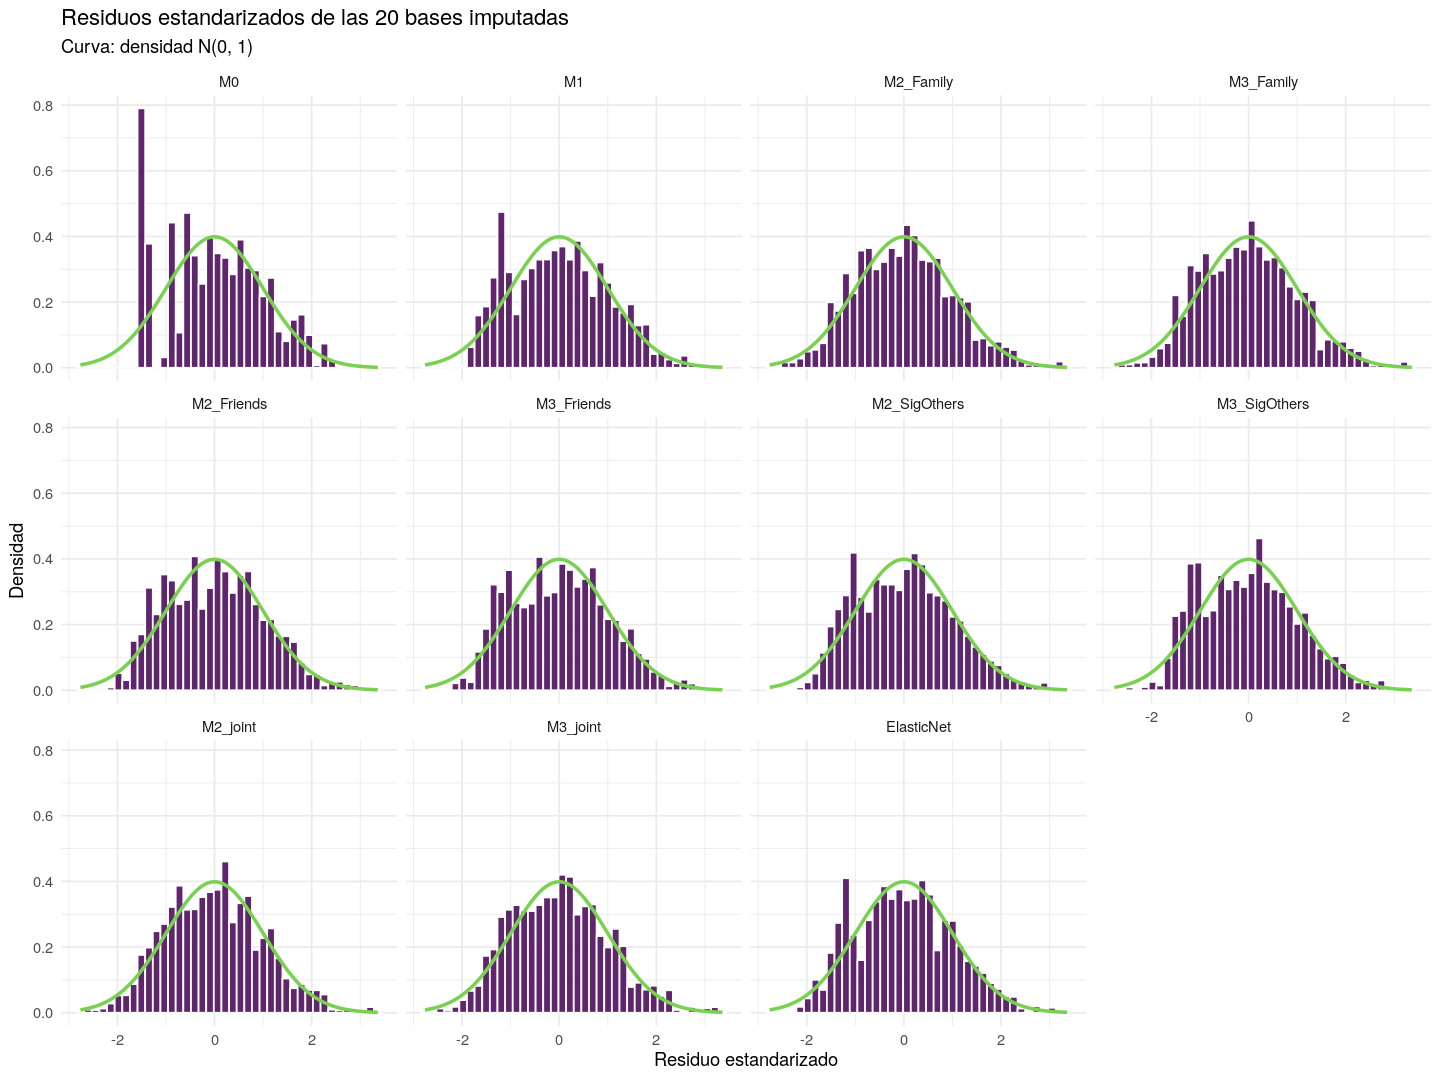

In [20]:
options(repr.plot.width = 12, repr.plot.height = 9)

ggplot(mi_diag, aes(x = std_resid)) +
  geom_histogram(aes(y = after_stat(density)), bins = 40,
                 fill = col_morado, color = "white", alpha = 0.85) +
  stat_function(fun = dnorm, color = col_verde, linewidth = 1) +
  facet_wrap(~ model, ncol = 4) +
  labs(title = "Residuos estandarizados de las 20 bases imputadas",
       subtitle = "Curva: densidad N(0, 1)",
       x = "Residuo estandarizado", y = "Densidad") +
  theme_minimal()

### *Gráficos Q-Q*

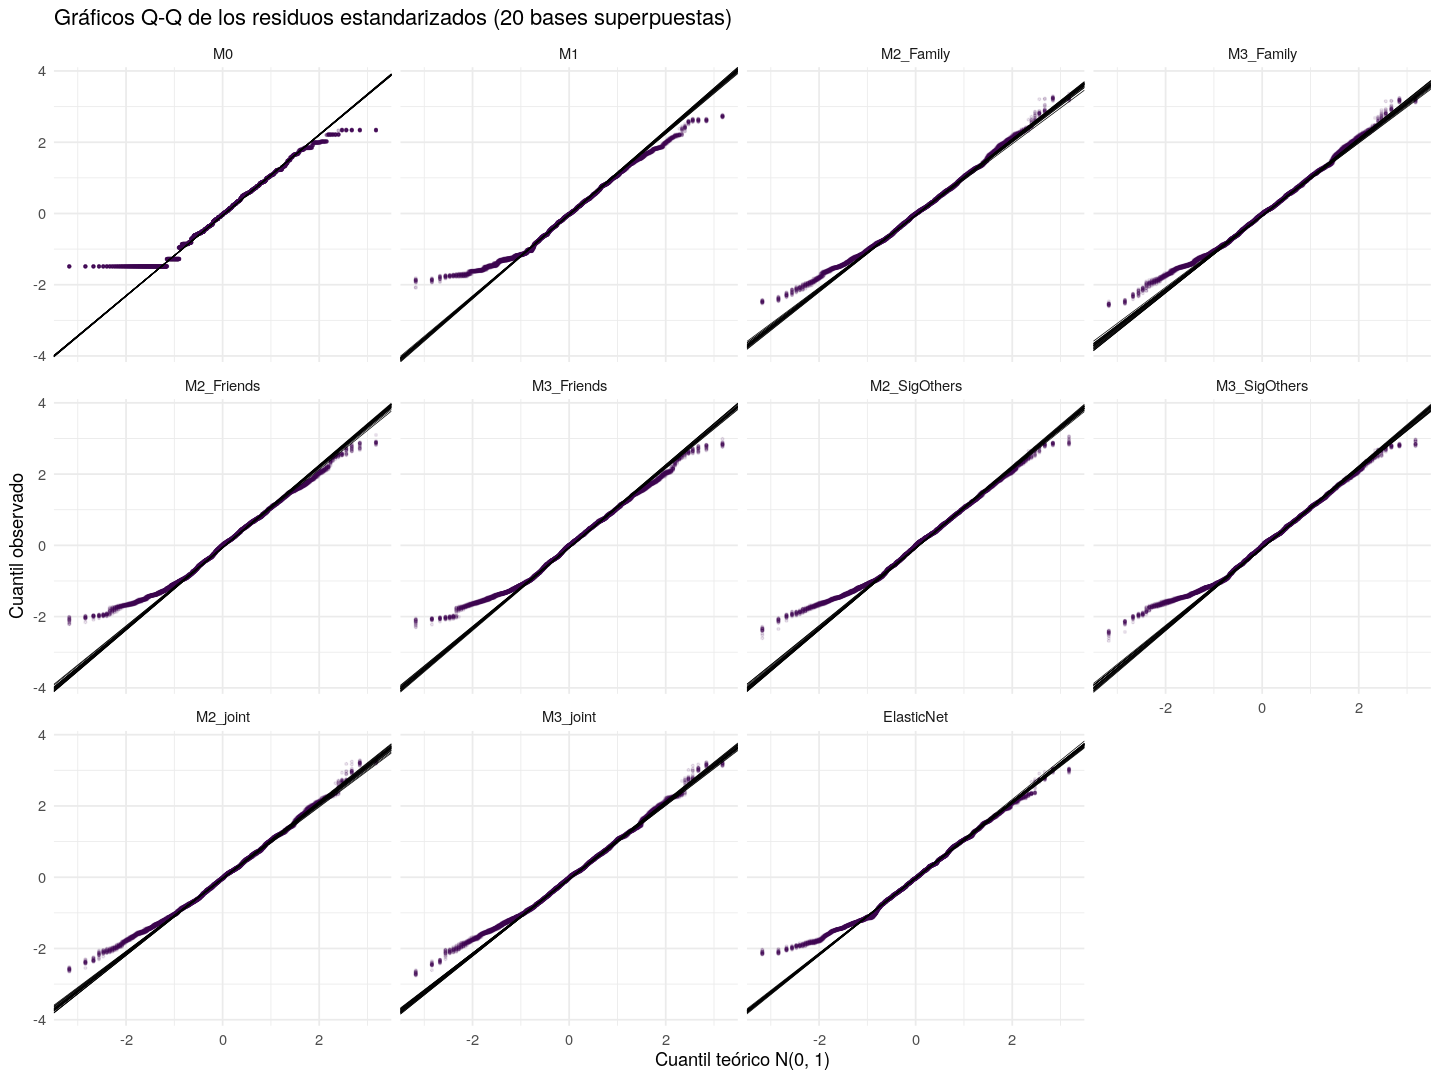

In [21]:
options(repr.plot.width = 12, repr.plot.height = 9)

ggplot(mi_diag, aes(sample = std_resid, group = imp)) +
  stat_qq(color = col_morado, alpha = 0.1, size = 0.5) +
  stat_qq_line(color = "black", linewidth = 0.2) +
  facet_wrap(~ model, ncol = 4) +
  labs(title = "Gráficos Q-Q de los residuos estandarizados (20 bases superpuestas)",
       x = "Cuantil teórico N(0, 1)", y = "Cuantil observado") +
  theme_minimal()

### *Residuos frente a valores ajustados*

Una curva suave por base. M0 se omite porque predice el mismo valor para todos.

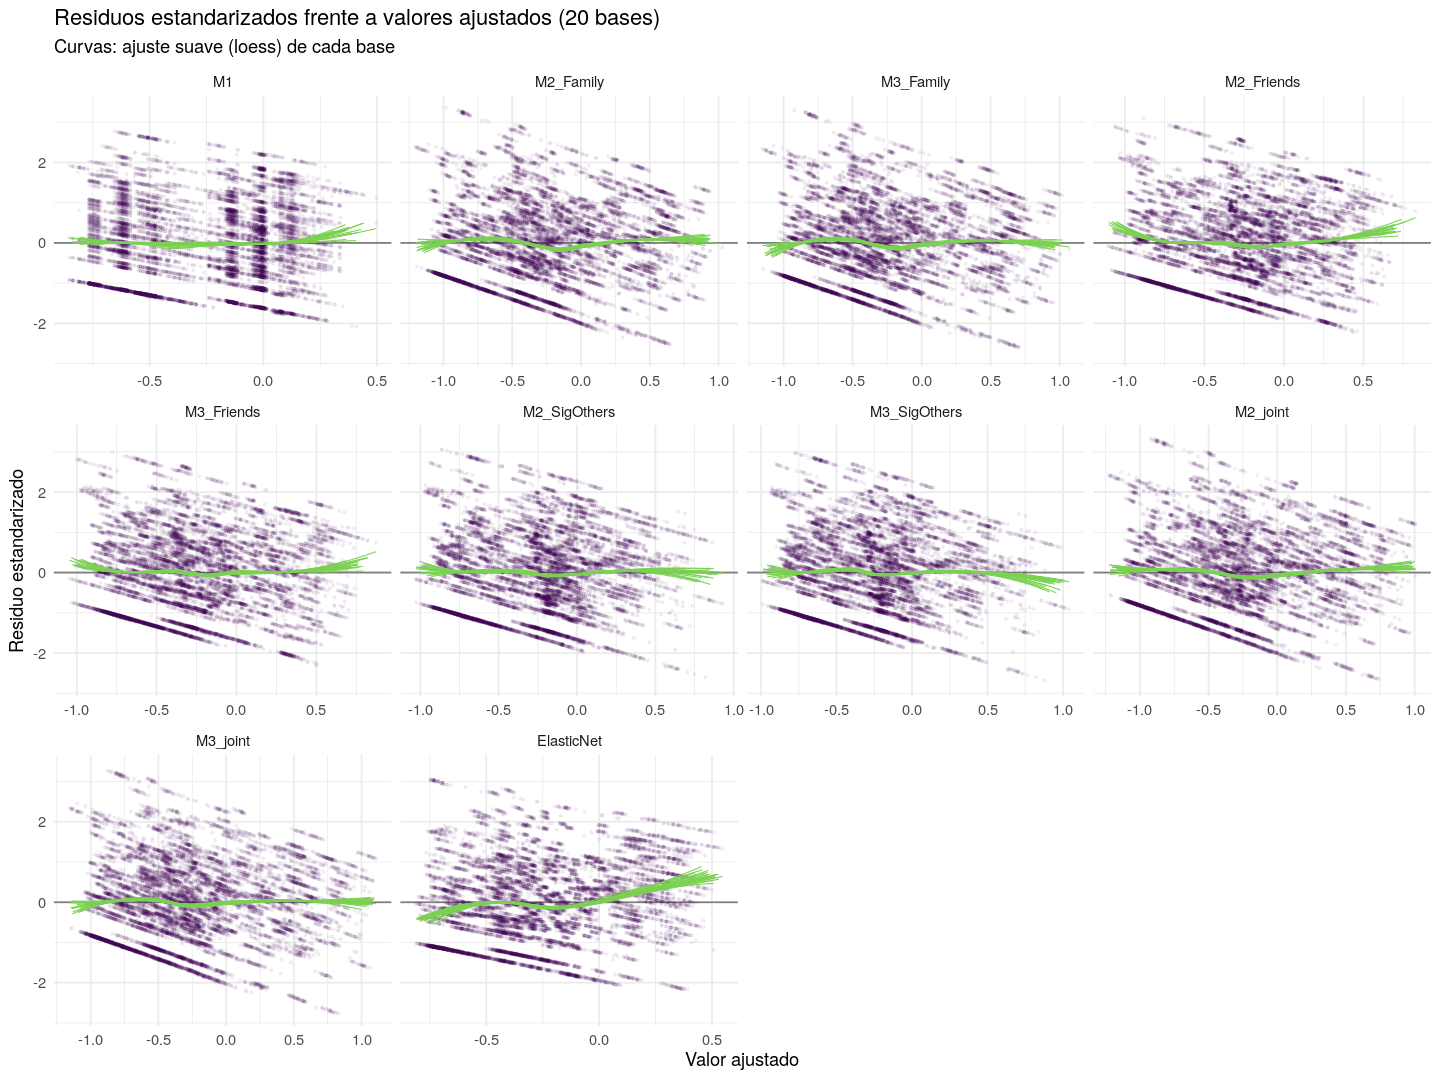

In [22]:
options(repr.plot.width = 12, repr.plot.height = 9)

mi_diag %>%
  filter(model != "M0") %>%
  ggplot(aes(x = fitted, y = std_resid)) +
  geom_hline(yintercept = 0, color = "grey50") +
  geom_point(color = col_morado, alpha = 0.05, size = 0.5) +
  geom_smooth(aes(group = imp), method = "loess", formula = y ~ x, se = FALSE,
              color = col_verde, linewidth = 0.3) +
  facet_wrap(~ model, ncol = 4, scales = "free_x") +
  labs(title = "Residuos estandarizados frente a valores ajustados (20 bases)",
       subtitle = "Curvas: ajuste suave (loess) de cada base",
       x = "Valor ajustado", y = "Residuo estandarizado") +
  theme_minimal()

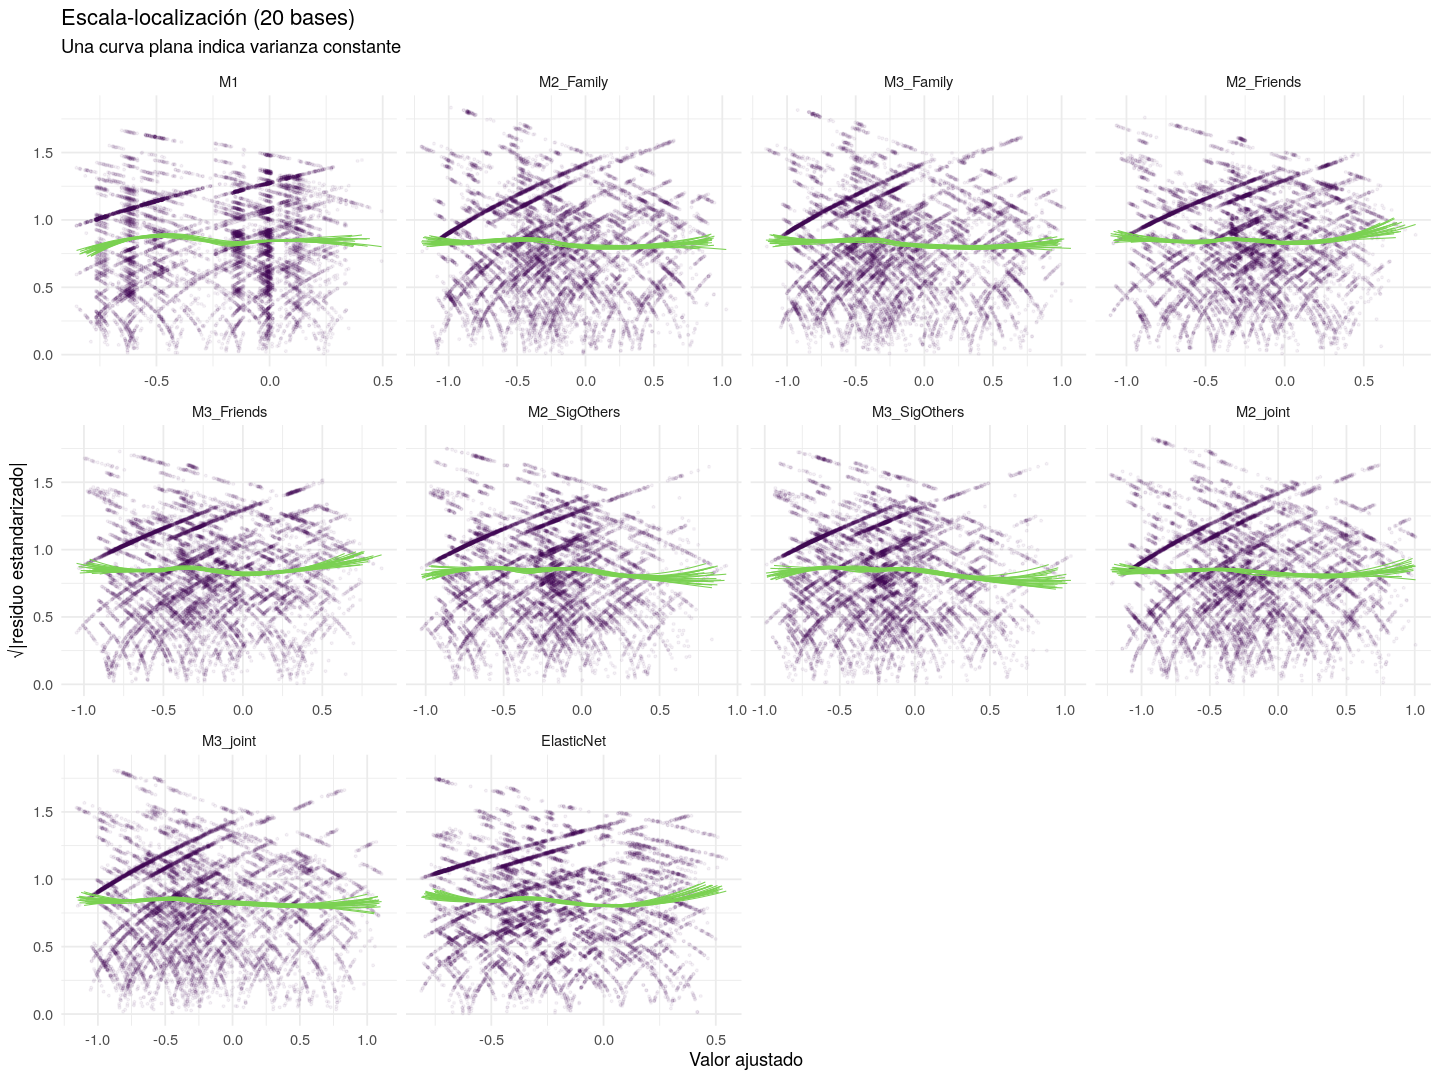

In [23]:
options(repr.plot.width = 12, repr.plot.height = 9)

mi_diag %>%
  filter(model != "M0") %>%
  ggplot(aes(x = fitted, y = sqrt(abs(std_resid)))) +
  geom_point(color = col_morado, alpha = 0.05, size = 0.5) +
  geom_smooth(aes(group = imp), method = "loess", formula = y ~ x, se = FALSE,
              color = col_verde, linewidth = 0.3) +
  facet_wrap(~ model, ncol = 4, scales = "free_x") +
  labs(title = "Escala-localización (20 bases)",
       subtitle = "Una curva plana indica varianza constante",
       x = "Valor ajustado", y = "√|residuo estandarizado|") +
  theme_minimal()

### *Leverage y puntos de apalancamiento*

Leverage frente a residuo studentizado, con las 20 bases superpuestas y el
tamaño según la distancia de Cook. Se omiten M0 y elastic net.

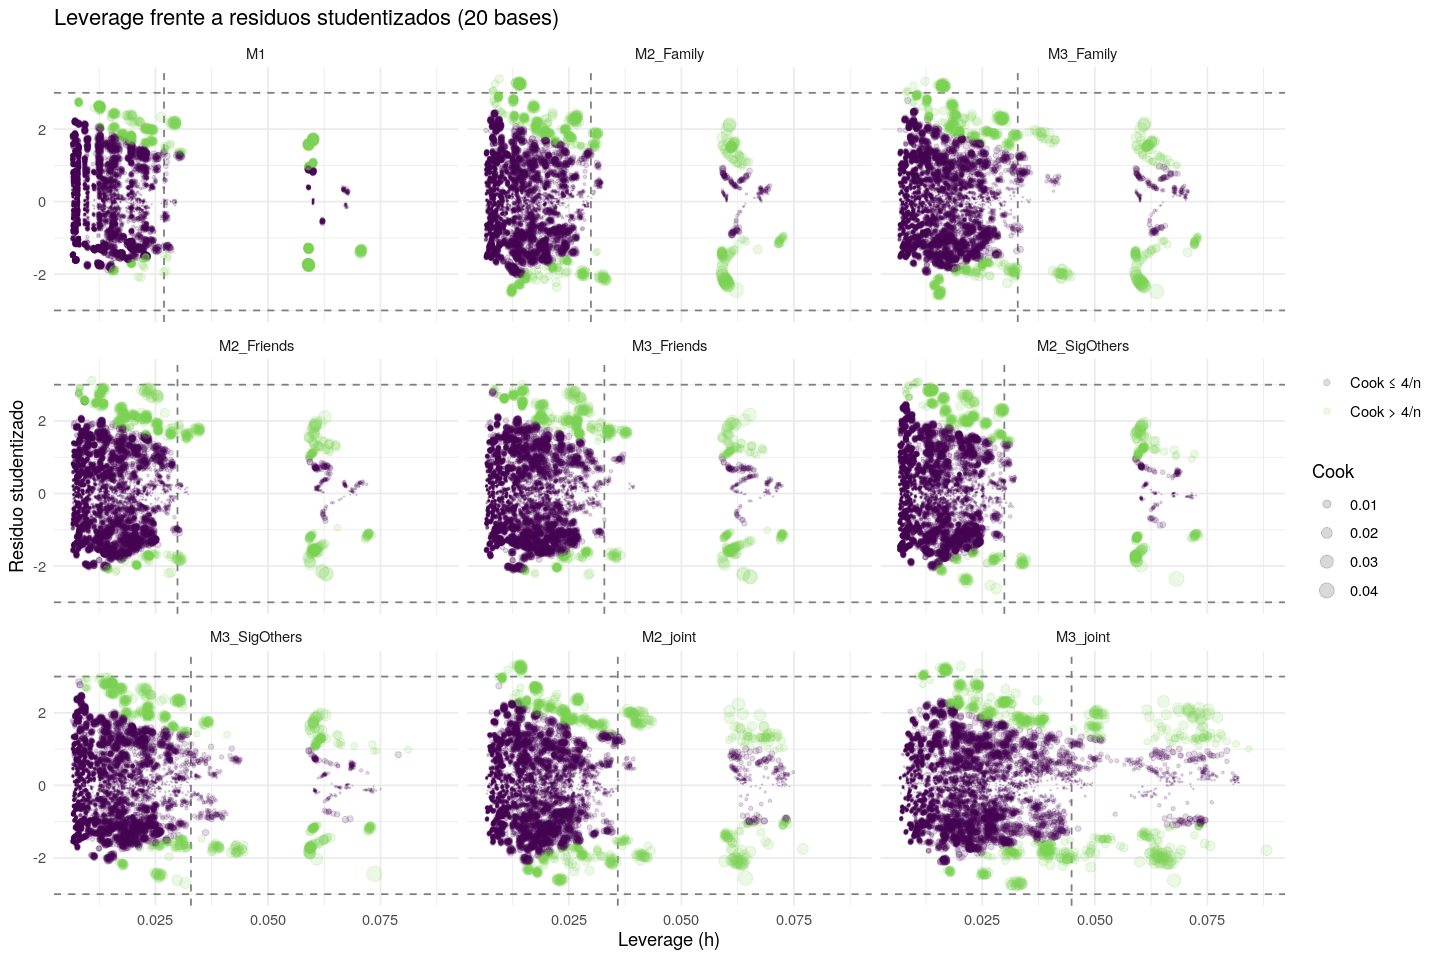

In [24]:
options(repr.plot.width = 12, repr.plot.height = 8)

mi_diag_lm <- mi_diag %>% filter(!is.na(leverage), model != "M0") %>% mutate(model = droplevels(model))

ggplot(mi_diag_lm, aes(x = leverage, y = stud_resid)) +
  geom_hline(yintercept = c(-DIAG_RESID_MAX, DIAG_RESID_MAX),
             linetype = "dashed", color = "grey50") +
  geom_vline(data = distinct(mi_diag_lm, model, leverage_cut),
             aes(xintercept = leverage_cut), linetype = "dashed", color = "grey50") +
  geom_point(aes(size = cooks_d, color = influential), alpha = 0.15) +
  scale_color_manual(values = c(`FALSE` = col_morado, `TRUE` = col_verde),
                     labels = c("Cook ≤ 4/n", "Cook > 4/n"), name = NULL) +
  scale_size_area(max_size = 4, name = "Cook") +
  facet_wrap(~ model, ncol = 3) +
  labs(title = "Leverage frente a residuos studentizados (20 bases)",
       x = "Leverage (h)", y = "Residuo studentizado") +
  theme_minimal()

In [25]:
# Municipio de los estudiantes con leverage alto en M2_joint, promedio de las 20 bases
map_dfr(seq_along(analytic), function(i) {
  alto <- mi_diag %>% filter(imp == i, model == "M2_joint") %>% pull(high_leverage)
  analytic[[i]] %>%
    mutate(alto = alto) %>%
    group_by(Municipality) %>%
    summarise(n = n(), n_leverage_alto = sum(alto), .groups = "drop")
}) %>%
  group_by(Municipality) %>%
  summarise(n = mean(n), n_leverage_alto = mean(n_leverage_alto), .groups = "drop") %>%
  mutate(pct_del_municipio = 100 * n_leverage_alto / n) %>%
  gt() %>%
  fmt_number(c(n, n_leverage_alto, pct_del_municipio), decimals = 1) %>%
  cols_label(Municipality = "Municipio", n = "n medio",
             n_leverage_alto = "n medio con leverage alto", pct_del_municipio = "% del municipio") %>%
  tab_header(title = "Leverage alto por municipio (M2_joint, promedio de las 20 bases)")

<div id="zjjtjvplfd" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#zjjtjvplfd table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#zjjtjvplfd thead, #zjjtjvplfd tbody, #zjjtjvplfd tfoot, #zjjtjvplfd tr, #zjjtjvplfd td, #zjjtjvplfd th {
  border-style: none;
}

#zjjtjvplfd p {
  margin: 0;
  padding: 0;
}

#zjjtjvplfd .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#zjjtjvplfd .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#zjjtjvplfd .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#zjjtjvplfd .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#zjjtjvplfd .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#zjjtjvplfd .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#zjjtjvplfd .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#zjjtjvplfd .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#zjjtjvplfd .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#zjjtjvplfd .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#zjjtjvplfd .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#zjjtjvplfd .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#zjjtjvplfd .gt_spanner_row {
  border-bottom-style: hidden;
}

#zjjtjvplfd .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Observaciones influyentes*

Estudiantes con distancia de Cook mayor que 4/n en al menos 8 de los 10 `lm()`,
y en cuántas de las 20 bases lo son. *Imputado* indica si el estudiante tiene
algún valor imputado. Se muestran los que son influyentes en al menos 10 bases.

In [26]:
mi_influential <- mi_influential_observations(mi_diag, analytic, imputed, min_models = 8)

mi_influential %>%
  filter(n_bases >= 10) %>%
  left_join(bases[[1]] %>% mutate(obs = row_number()) %>%
              select(obs, Gender, Municipality), by = "obs") %>%
  gt() %>%
  fmt_number(c(max_cooks, max_abs_t, max_lev), decimals = 3) %>%
  text_transform(locations = cells_body(columns = imputed),
                 fn = function(x) ifelse(x == "TRUE", "sí", "no")) %>%
  cols_label(obs = "Fila", n_bases = "Bases (de 20)", max_cooks = "Cook máximo",
             max_abs_t = "|t| máximo", max_lev = "Leverage máximo", imputed = "Imputado",
             Gender = "Género", Municipality = "Municipio") %>%
  tab_header(title = "Observaciones influyentes en la mayoría de los modelos")

<div id="ojjrgdmgtm" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#ojjrgdmgtm table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#ojjrgdmgtm thead, #ojjrgdmgtm tbody, #ojjrgdmgtm tfoot, #ojjrgdmgtm tr, #ojjrgdmgtm td, #ojjrgdmgtm th {
  border-style: none;
}

#ojjrgdmgtm p {
  margin: 0;
  padding: 0;
}

#ojjrgdmgtm .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#ojjrgdmgtm .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#ojjrgdmgtm .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#ojjrgdmgtm .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#ojjrgdmgtm .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#ojjrgdmgtm .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#ojjrgdmgtm .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#ojjrgdmgtm .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#ojjrgdmgtm .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#ojjrgdmgtm .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#ojjrgdmgtm .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#ojjrgdmgtm .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#ojjrgdmgtm .gt_spanner_row {
  border-bottom-style: hidden;
}

#ojjrgdmgtm .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Guardado*

- `outputs/models/mi_pipeline.rds`: modelos `lm()` y elastic net de las 20 bases.
- `outputs/tables/mi_coefficients.csv`: coeficientes combinados (Rubin).
- `outputs/tables/mi_fit_indices.csv`: índices de ajuste promediados.
- `outputs/tables/mi_nested.csv`: comparaciones anidadas promediadas.
- `outputs/tables/mi_cv_fold_metrics.csv`: métricas por base, partición y modelo.
- `outputs/tables/mi_cv_summary.csv`: validación cruzada combinada.
- `outputs/tables/mi_assumption_tests.csv`: pruebas de supuestos por base.
- `outputs/tables/mi_diagnostics_summary.csv`: diagnóstico promediado.

In [27]:
saved <- save_mi_outputs(
  tables = list(coefficients = coef_mi, indices = mi_indices, nested = mi_nested,
                cv_folds = mi_cv, cv_summary = mi_cv_summary,
                assumptions = mi_assumptions, diagnostics = mi_diag_summary),
  models = list(lm = mi_models, en = en_models, params = mi_params)
)

cat(paste(saved, collapse = "\n"), "\n")

outputs/tables/mi_coefficients.csv
outputs/tables/mi_fit_indices.csv
outputs/tables/mi_nested.csv
outputs/tables/mi_cv_fold_metrics.csv
outputs/tables/mi_cv_summary.csv
outputs/tables/mi_assumption_tests.csv
outputs/tables/mi_diagnostics_summary.csv
outputs/models/mi_pipeline.rds 
